# Visualisasi — Alur dan Sekuens (jalur pengguna, funnel, retensi, transisi)
**Kapan dipakai:** "ke mana pengguna pergi setelah langkah ini? di tahap mana mereka berhenti?
berapa persen yang kembali bulan depan? item mana sering muncul bersama?"

**Isi:** Sankey jalur, sunburst jalur, funnel konversi, heatmap cohort/retensi bulanan, heatmap
transisi antar event, heatmap lift ko-pembelian. Semua gambar disimpan di folder notebook.

**Data demo:** MovieLens 100k (urutan film yang dinilai tiap pengguna), Online Retail
(pelanggan dan tanggal belanja), Groceries (keranjang belanja).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan"   # GANTI saat lomba
RATINGS_CSV = f"{DATA_FOLDER}/recsys/ml-100k/ratings.csv"
MOVIES_CSV = f"{DATA_FOLDER}/recsys/ml-100k/movies.csv"
RETAIL_CSV = f"{DATA_FOLDER}/unsupervised/online_retail.csv"
BASKETS_CSV = f"{DATA_FOLDER}/unsupervised/groceries.csv"   # satu baris = satu keranjang

TOP_GENRES = 6     # jumlah genre yang ditampilkan di Sankey (sisanya "Lainnya")
TOP_ITEMS = 12     # jumlah item terpopuler di heatmap lift
# tahap funnel: nama -> minimal jumlah pembelian
FUNNEL_STAGES = {"Semua pelanggan": 1, "Beli >= 2 kali": 2, "Beli >= 3 kali": 3,
                 "Beli >= 5 kali": 5, "Beli >= 10 kali": 10}

## Gaya grafik (sama di semua notebook visualisasi)
Font besar supaya terbaca di slide, palet tetap, garis tepi atas/kanan dimatikan.

In [3]:
PALETTE = ["#2E6FB7", "#F28E2B", "#3BA272", "#D1495B", "#7B5EA7", "#9AA0A6"]
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = PALETTE
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 14, "axes.titlesize": 18, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## Siapkan urutan event: genre film yang dinilai tiap pengguna
Event = satu rating, urutan = menurut waktu. `genre` = genre pertama yang bernilai 1 di data film.

In [4]:
ratings = pd.read_csv(RATINGS_CSV)
movies = pd.read_csv(MOVIES_CSV)
genre_cols = list(movies.columns[3:])
movies["genre"] = movies[genre_cols].idxmax(axis=1)
movie_genre = dict(zip(movies["item"], movies["genre"]))
ratings["genre"] = ratings["item"].map(movie_genre)
ratings = ratings.sort_values(["user", "timestamp"])
ratings["step"] = ratings.groupby("user").cumcount()           # 0 = film pertama
ratings["next_genre"] = ratings.groupby("user")["genre"].shift(-1)

first_steps = ratings[ratings["step"] < 3].pivot(index="user", columns="step", values="genre")
first_steps.columns = ["langkah1", "langkah2", "langkah3"]
print(ratings.shape, first_steps.shape)
first_steps.head(3)

(100000, 7) (943, 3)


,langkah1,langkah2,langkah3
user,,,
1,Comedy,Action,Drama
2,Drama,Drama,Drama
3,Action,Crime,Mystery


## 1. Sankey jalur
**Kapan dipakai:** menunjukkan arus dari satu tahap ke tahap berikutnya (klik, halaman,
pembelian, perpindahan status). **Cara baca:** lebar pita = jumlah pengguna, tiap kolom =
satu langkah. Pita tebal yang berpindah warna = perpindahan yang sering. Interaktif: arahkan
kursor ke pita untuk melihat jumlahnya.

Plotly Sankey butuh nomor simpul: simpul = (langkah, genre), nomor = langkah x jumlah genre +
posisi genre.

In [5]:
top_genres = list(first_steps["langkah1"].value_counts().head(TOP_GENRES).index)
genres = top_genres + ["Lainnya"]
sankey_table = first_steps.copy()
for column in sankey_table.columns:
    is_top = sankey_table[column].isin(genres)
    sankey_table[column] = sankey_table[column].where(is_top, "Lainnya")

node_names = []
node_colors = []
for column in sankey_table.columns:
    for i, genre in enumerate(genres):
        node_names.append(f"{genre} ({column[-1]})")
        node_colors.append(PALETTE[i % len(PALETTE)])

sources = []
targets = []
values = []
for step in range(2):
    pairs = sankey_table.groupby([f"langkah{step + 1}", f"langkah{step + 2}"]).size()
    for pair, count in pairs.items():
        sources.append(step * len(genres) + genres.index(pair[0]))
        targets.append((step + 1) * len(genres) + genres.index(pair[1]))
        values.append(count)

fig = go.Figure(go.Sankey(node={"label": node_names, "color": node_colors, "pad": 15},
                          link={"source": sources, "target": targets, "value": values}))
fig.update_layout(title="Genre pada 3 film pertama yang dinilai tiap pengguna", font_size=14)
fig.write_html("alur_sankey.html", include_plotlyjs=True)
fig.show()

## 2. Sunburst jalur
**Kapan dipakai:** jalur bercabang banyak yang ingin dijelajahi sebagai pohon.
**Cara baca:** lingkaran dalam = langkah 1, luar = langkah berikutnya, lebar busur = jumlah
pengguna. Klik sebuah busur untuk memperbesar cabang itu.

In [6]:
fig = px.sunburst(first_steps.dropna(), path=["langkah1", "langkah2", "langkah3"],
                  color_discrete_sequence=PALETTE, title="Jalur tiga genre pertama")
fig.update_layout(font_size=14)
fig.write_html("alur_sunburst.html", include_plotlyjs=True)
fig.show()

## Siapkan funnel dan cohort: Online Retail

In [7]:
retail = pd.read_csv(RETAIL_CSV, parse_dates=["InvoiceDate"],
                     usecols=["InvoiceNo", "CustomerID", "InvoiceDate"])
retail = retail.dropna(subset=["CustomerID"])
invoice_numbers = retail["InvoiceNo"].astype(str)
retail = retail[~invoice_numbers.str.startswith("C")]   # faktur berawalan C = pembatalan
print(retail.shape, retail["InvoiceDate"].min().date(), "s.d.", retail["InvoiceDate"].max().date())

(161750, 3) 2010-12-01 s.d. 2011-12-09


## 3. Funnel konversi per tahap
**Kapan dipakai:** proses berurutan di mana jumlah makin menyusut (kunjungan, daftar, beli,
atau pembeli pertama, kedua, ketiga). **Cara baca:** lebar batang = jumlah pelanggan di tahap
itu, persen dalam batang = sisa dari tahap pertama, teks abu = persen yang lanjut dari tahap
sebelumnya.

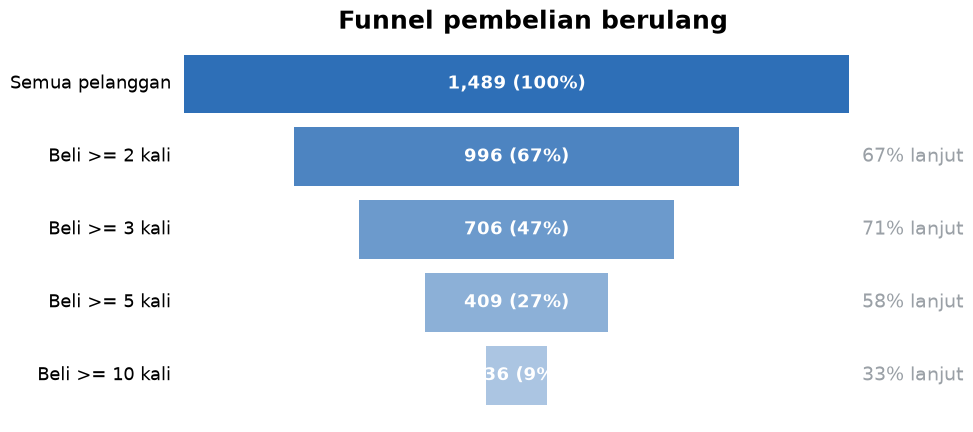

In [8]:
orders = retail.groupby("CustomerID")["InvoiceNo"].nunique()   # jumlah faktur per pelanggan
stage_names = list(FUNNEL_STAGES.keys())
stage_counts = []
for minimum in FUNNEL_STAGES.values():
    stage_counts.append(int((orders >= minimum).sum()))
first_count = stage_counts[0]

plt.figure(figsize=(9, 5))
for i in range(len(stage_names)):
    count = stage_counts[i]
    plt.barh(i, count, left=-count / 2, color=BLUE, alpha=1 - 0.15 * i)   # batang di tengah
    plt.text(-first_count / 2 - 30, i, stage_names[i], ha="right", va="center", fontsize=13)
    plt.text(0, i, f"{count:,} ({count / first_count:.0%})", ha="center", va="center",
             color="white", fontsize=13, fontweight="bold")
    if i > 0:
        continue_share = count / stage_counts[i - 1]
        plt.text(first_count / 2 + 30, i, f"{continue_share:.0%} lanjut", va="center", color=GREY)
plt.gca().invert_yaxis()
plt.axis("off")
plt.title("Funnel pembelian berulang")
# Alternatif interaktif: px.funnel(x=stage_counts, y=stage_names)
plt.savefig("alur_funnel.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Heatmap cohort / retensi bulanan
**Kapan dipakai:** menjawab "dari pelanggan yang pertama kali beli bulan X, berapa persen masih
beli sesudahnya?" **Cara baca:** baris = bulan pertama beli (cohort), kolom = berapa bulan
sesudahnya, isi = persen cohort itu yang aktif. Kolom 0 selalu 100%. Warna cepat memudar =
retensi buruk. Baris yang lebih gelap dari baris atasnya = cohort yang lebih setia.

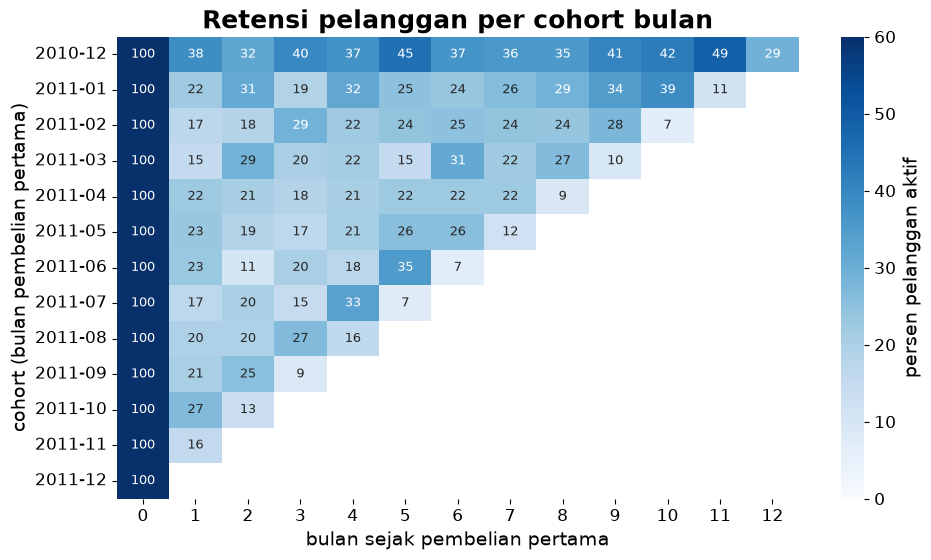

In [9]:
retail["month"] = retail["InvoiceDate"].dt.year * 12 + retail["InvoiceDate"].dt.month
retail["first_month"] = retail.groupby("CustomerID")["month"].transform("min")
retail["months_since"] = retail["month"] - retail["first_month"]
active = retail.groupby(["first_month", "months_since"])["CustomerID"].nunique()
active = active.unstack()                      # baris = cohort, kolom = bulan sejak awal
retention = active.div(active[0], axis=0) * 100

cohort_names = []
for month in retention.index:
    year = (month - 1) // 12
    month_number = (month - 1) % 12 + 1
    cohort_names.append(f"{year}-{month_number:02d}")
retention.index = cohort_names

plt.figure(figsize=(11, 6))
sns.heatmap(retention, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=60,
            cbar_kws={"label": "persen pelanggan aktif"}, annot_kws={"size": 9})
plt.title("Retensi pelanggan per cohort bulan")
plt.xlabel("bulan sejak pembelian pertama")
plt.ylabel("cohort (bulan pembelian pertama)")
plt.grid(False)
plt.savefig("alur_cohort_retensi.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Heatmap transisi antar event
**Kapan dipakai:** urutan event/kategori, "setelah A biasanya apa?" (dasar rantai Markov dan
rekomendasi berikutnya). **Cara baca:** baris = event sekarang, kolom = event berikutnya, isi =
persen (tiap baris berjumlah 100%). Diagonal tebal = pengguna cenderung mengulang jenis yang sama.

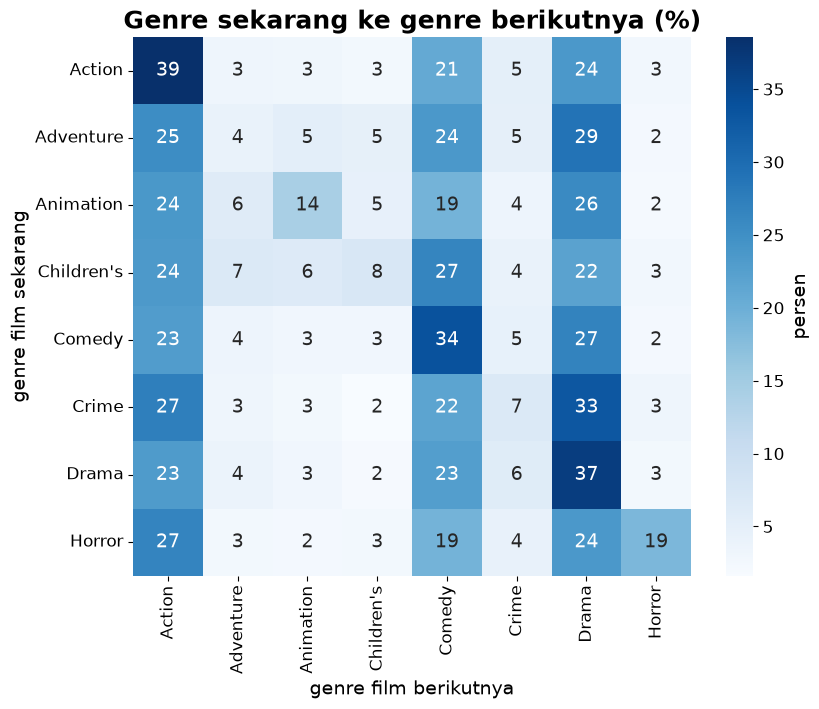

In [10]:
big_genres = ratings["genre"].value_counts().head(8).index
has_genre = ratings["genre"].isin(big_genres)
has_next = ratings["next_genre"].isin(big_genres)
transitions = ratings[has_genre & has_next]
transition_table = pd.crosstab(transitions["genre"], transitions["next_genre"],
                               normalize="index") * 100
plt.figure(figsize=(9, 7))
sns.heatmap(transition_table, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "persen"})
plt.title("Genre sekarang ke genre berikutnya (%)")
plt.xlabel("genre film berikutnya")
plt.ylabel("genre film sekarang")
plt.grid(False)
plt.savefig("alur_transisi.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Heatmap lift ko-pembelian (keranjang belanja)
**Kapan dipakai:** data keranjang, item mana sering dibeli bersama melebihi kebetulan.
**Cara baca:** lift = peluang dua item bersama dibanding bila saling bebas. Lift > 1 (biru tua)
= saling menarik, sekitar 1 = tidak ada hubungan. Dasar aturan asosiasi dan bundling.

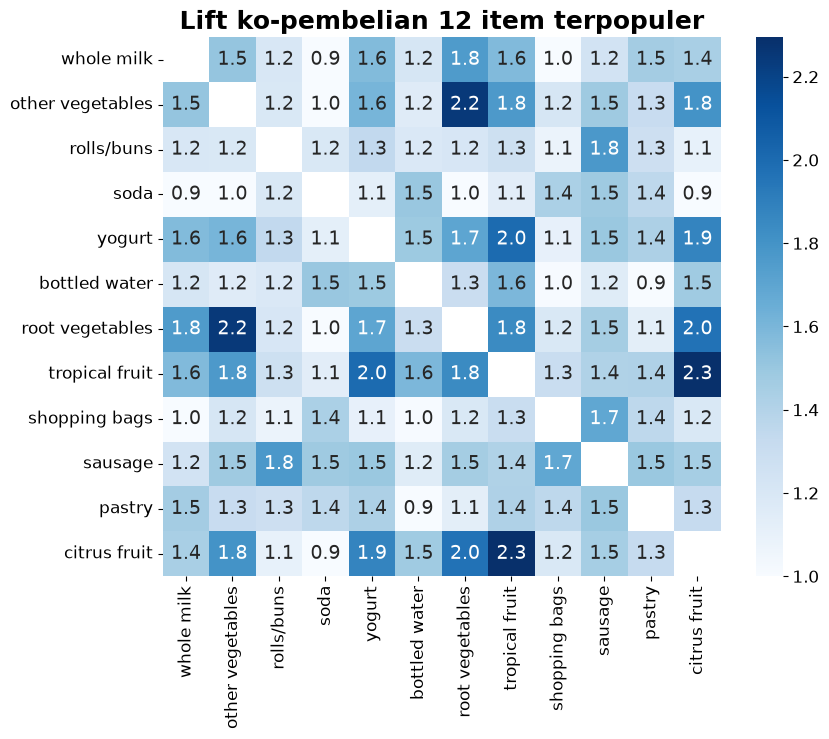

In [11]:
basket_lines = open(BASKETS_CSV, encoding="utf-8").read().splitlines()
baskets = pd.Series(basket_lines).str.get_dummies(",")   # 1 kolom per item, isi 0/1
popular = baskets.sum().nlargest(TOP_ITEMS).index
contents = baskets[popular]
together = contents.T @ contents                         # jumlah keranjang berisi kedua item
item_counts = contents.sum()
lift = together * len(contents) / np.outer(item_counts, item_counts)
plt.figure(figsize=(9, 7))
sns.heatmap(lift, mask=np.eye(TOP_ITEMS, dtype=bool), annot=True, fmt=".1f", cmap="Blues", vmin=1)
plt.title(f"Lift ko-pembelian {TOP_ITEMS} item terpopuler")
plt.grid(False)
plt.savefig("alur_lift_keranjang.png", dpi=200, bbox_inches="tight")
plt.show()